# MS-BART Fine-Tuning for Molecular Structure Generation

**Student:** Stephanie Nord  
**Course:** DSC 670 – Generative AI  
**Instructor:** Professor Neugebauer  
**Assignment:** Week 8 – 8.3 Project Milestone 3: Build Your First Model  
**Institution:** Bellevue University  
**Due Date:** November 1, 2026

---

**Reproducibility Note**

This notebook preserves the original full-parameter MS-BART fine-tuning workflow and its experimental outputs. Model inference was performed in the `ms_bart` Conda environment, while the independently reproduced molecular similarity evaluation was performed using RDKit in a separate environment because Windows Application Control blocked an RDKit compiled library in the original environment. The saved prediction files, evaluation script, and similarity results allow the analysis to be reproduced without repeating model training. The notebook should not be executed using Run All without first reviewing the checkpoint-saving and training cells.

## 1. Research Objective and Experimental Design

**Research Objective:** Investigate whether full-parameter supervised fine-tuning improves molecular structure generation from MIST-derived fingerprint representations.

**Experimental Approach:** Compare a pretrained MS-BART encoder-decoder model with a version fine-tuned on 128 fingerprint-to-SELFIES training pairs. Both models are evaluated using the same 32 held-out validation examples.

**Research Question:** Does full-parameter fine-tuning improve molecular validity, exact molecular identification, or structural similarity compared with the pretrained model?

This experiment evaluates the fingerprint-to-SELFIES stage of molecular structure generation rather than predicting molecular structures directly from raw MS/MS spectra. Full-parameter fine-tuning was performed using a pretrained MS-BART encoder-decoder model (Han et al., 2025), with PyTorch and an NVIDIA GPU, without LoRA. SMILES provides a text-based representation of molecular connectivity, while SELFIES uses a constrained molecular representation designed to support valid molecular generation (Krenn et al., 2020; Weininger, 1988). In this experiment, SELFIES sequences served as the model's training targets, and RDKit was used to convert the generated structures into canonical SMILES for comparison with reference molecules.

## 2. Computational Environment

### 2.1 GPU and PyTorch Verification

In [6]:
import sys
import torch

print("Environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print(
    "Total GPU memory (GB):",
    round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1)
)

free_bytes, total_bytes = torch.cuda.mem_get_info()
print("Free GPU memory (GB):", round(free_bytes / 1e9, 1))

Environment: C:\Users\sfnor\miniconda3\envs\ms_bart\python.exe
PyTorch: 2.8.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Total GPU memory (GB): 8.5
Free GPU memory (GB): 6.8


### 2.2 Project Directory and Data Files

In [1]:
from pathlib import Path

project_dir = Path.cwd().parent
data_dir = project_dir / "ms_bart_pilot" / "data"

print("Notebook working directory:", Path.cwd())
print("Data directory:", data_dir)
print("Directory exists:", data_dir.is_dir())

if data_dir.is_dir():
    for path in sorted(data_dir.iterdir()):
        if path.is_file():
            print(f"{path.name} — {path.stat().st_size / 1_000_000:.1f} MB")

Notebook working directory: C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot
Data directory: C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot\data
Directory exists: True
MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 14.7 MB
only_h_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 104.4 MB
val_candidate_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 16.9 MB


In [2]:
for path in sorted(project_dir.rglob("*fps_selfies*.tsv")):
    print(path.relative_to(project_dir), f"— {path.stat().st_size / 1_000_000:.1f} MB")

ms_bart_pilot\data\MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 14.7 MB
ms_bart_pilot\data\only_h_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 104.4 MB
ms_bart_pilot\data\val_candidate_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv — 16.9 MB


## 3. Dataset Acquisition and Preparation

The dataset files were retrieved from a publicly accessible Figshare repository containing MassSpecGym–MIST fingerprint-to-SELFIES representations (Bushuiev et al., 2024; Han et al., 2025). I examined the available files and their sizes before selecting the training and validation sources. Because multiple files had similar names, the dataset partitions were subsequently inspected to verify their contents, fold assignments, and separation before sampling the pilot examples.

### 3.1 Dataset Source and File Selection

In [5]:
import json
from urllib.request import urlopen

url = "https://api.figshare.com/v2/articles/30393544"

with urlopen(url, timeout=30) as response:
    files = json.load(response)["files"]

relevant_files = [
    file for file in files
    if "MassSpecGym-MIST" in file["name"]
]

print("Relevant dataset files:", len(relevant_files))

for file in relevant_files:
    print(
        file["name"],
        f"- {file['size'] / 1_000_000:.1f} MB"
    )

Relevant dataset files: 3
MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv - 16.9 MB
only_h_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv - 104.4 MB
MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv - 14.7 MB


### 3.2 Dataset Download

In [4]:
from urllib.request import urlretrieve

name = "only_h_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv"
file_info = next(f for f in files if f["name"] == name)
destination = data_dir / name

urlretrieve(file_info["download_url"], destination)
print("Downloaded:", destination)
print("Size:", round(destination.stat().st_size / 1_000_000, 1), "MB")

Downloaded: C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot\data\only_h_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv
Size: 104.4 MB


### 3.3 Dataset Structure and Initial Inspection

In [5]:
import pandas as pd

preview = pd.read_csv(destination, sep="\t", nrows=3)
print("Columns:", preview.columns.tolist())
display(preview.head(3))

Columns: ['identifier', 'fps', 'selfies', 'smiles', 'inchikey', 'formula', 'adduct', 'fold']


,identifier,fps,selfies,smiles,inchikey,formula,adduct,fold
0,MassSpecGymID0000001,<fp0117><fp0245><fp0291><fp0322><fp0389><fp065...,[C][O][C][C][=C][Branch2][Ring1][Ring1][C@H1][...,CC(=O)N[C@@H](CC1=CC=CC=C1)C2=CC(=CC(=O)O2)OC,VFMQMACUYWGDOJ,C16H17NO4,[M+H]+,train
1,MassSpecGymID0000002,<fp0117><fp0245><fp0291><fp0322><fp0389><fp065...,[C][O][C][C][=C][Branch2][Ring1][Ring1][C@H1][...,CC(=O)N[C@@H](CC1=CC=CC=C1)C2=CC(=CC(=O)O2)OC,VFMQMACUYWGDOJ,C16H17NO4,[M+H]+,train
2,MassSpecGymID0000003,<fp0291><fp0322><fp0389><fp0656><fp0695><fp080...,[C][O][C][C][=C][Branch2][Ring1][Ring1][C@H1][...,CC(=O)N[C@@H](CC1=CC=CC=C1)C2=CC(=CC(=O)O2)OC,VFMQMACUYWGDOJ,C16H17NO4,[M+H]+,train


In [6]:
folds = pd.read_csv(destination, sep="\t", usecols=["fold"])
print(folds["fold"].value_counts(dropna=False))

fold
train    166479
Name: count, dtype: int64


### 3.4 Validation Dataset Acquisition and Schema Verification

In [7]:
val_info = next(
    f for f in files
    if f["name"] == "MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv"
    and 16_000_000 < f["size"] < 18_000_000
)

val_candidate = data_dir / "val_candidate_MassSpecGym-MIST_fps_selfies_threshold_0.11.tsv"
urlretrieve(val_info["download_url"], val_candidate)

val_folds = pd.read_csv(val_candidate, sep="\t", usecols=["fold"])
print("Size:", round(val_candidate.stat().st_size / 1_000_000, 1), "MB")
print(val_folds["fold"].value_counts(dropna=False))

Size: 16.9 MB
fold
val    19429
Name: count, dtype: int64


In [8]:
train_columns = pd.read_csv(destination, sep="\t", nrows=0).columns.tolist()
val_columns = pd.read_csv(val_candidate, sep="\t", nrows=0).columns.tolist()

print("Training columns:", train_columns)
print("Validation columns:", val_columns)
print("Same columns:", train_columns == val_columns)

Training columns: ['identifier', 'fps', 'selfies', 'smiles', 'inchikey', 'formula', 'adduct', 'fold']
Validation columns: ['identifier', 'fps', 'selfies', 'smiles', 'inchikey', 'formula', 'adduct', 'fold']
Same columns: True


In [9]:
check_columns = ["identifier", "fps", "selfies"]

train_check = pd.read_csv(destination, sep="\t", usecols=check_columns)
val_check = pd.read_csv(val_candidate, sep="\t", usecols=check_columns)

print("Training missing values:")
print(train_check.isna().sum())

print("\nValidation missing values:")
print(val_check.isna().sum())

shared_ids = set(train_check["identifier"]) & set(val_check["identifier"])
print("\nIdentifiers in both splits:", len(shared_ids))

Training missing values:
identifier    0
fps           0
selfies       0
dtype: int64

Validation missing values:
identifier    0
fps           0
selfies       0
dtype: int64

Identifiers in both splits: 0


In [10]:
train_keys = pd.read_csv(destination, sep="\t", usecols=["inchikey"])
val_keys = pd.read_csv(val_candidate, sep="\t", usecols=["inchikey"])

shared_molecules = set(train_keys["inchikey"].dropna()) & set(
    val_keys["inchikey"].dropna()
)

print("Molecules in both splits:", len(shared_molecules))

Molecules in both splits: 0


The training and validation files contained the same eight columns: `identifier`, `fps`, `selfies`, `smiles`, `inchikey`, `formula`, `adduct`, and `fold`. The training partition contained 166,479 records, while the validation partition contained 19,429. Neither partition contained missing values in the three fields needed for this experiment: `identifier`, `fps`, and `selfies`.

I also examined identifier and InChIKey overlap between the source partitions. Both checks returned zero shared values, providing evidence that the source datasets were separated before selecting the pilot samples. These checks do not establish that every possible chemically equivalent representation or any overlap with the model's original pretraining data has been excluded.

### 3.5 Pilot Subset Selection

In [11]:
train_small = train_check.sample(n=128, random_state=42).reset_index(drop=True)
val_small = val_check.sample(n=32, random_state=42).reset_index(drop=True)

print("Pilot training rows:", len(train_small))
print("Pilot validation rows:", len(val_small))
display(train_small.head(3))

Pilot training rows: 128
Pilot validation rows: 32


,identifier,fps,selfies
0,MassSpecGymID0083940,<fp0099><fp0389><fp0638><fp1004><fp1066><fp108...,[C][C][Branch1][C][C][Branch1][C][N][C][C][=C]...
1,MassSpecGymID0098558,<fp0245><fp0389><fp0656><fp0695><fp0807><fp106...,[C][C@@H1][C][C@@][Branch1][=Branch1][O][C@H1]...
2,MassSpecGymID0172555,<fp0647><fp0875><fp1088><fp1380><fp1470><fp169...,[O][C][=C][C][=C][NH1][C][=C][C][Ring1][Branch...


For this pilot experiment, I randomly selected 128 training examples and 32 validation examples using a fixed random seed of 42. The reduced sample sizes were chosen to make full-parameter fine-tuning feasible on the available local GPU while preserving a separate validation sample for evaluating predictions. These subsets were sufficient for testing the training workflow, but the small sample sizes limit the conclusions that can be drawn about generalization and molecular identification performance.

## 4. Pretrained Model and GPU Setup

### 4.1 Model Weights and Tokenizer Preparation

The pretrained MS-BART model was used as the starting point for this experiment (Han et al., 2025). The model weights and tokenizer files were stored locally and loaded using Hugging Face Transformers. This allowed the pretrained encoder-decoder architecture to be used for baseline inference and subsequent full-parameter fine-tuning without relying on a hosted model API.

Before training, I examined the tokenized lengths of the fingerprint inputs and SELFIES targets to understand the sequence sizes required by the model.

In [12]:
for path in project_dir.rglob("pytorch_model.bin"):
    print (path.parent)
    print("Weight file size:", round(path.stat().st_size / 1_000_000, 1), "MB")

C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot\model-weights
Weight file size: 416.5 MB


In [14]:
from transformers import BartTokenizer

model_dir = project_dir / "ms_bart_pilot" / "model-weights"
tokenizer = BartTokenizer.from_pretrained(model_dir)

input_lengths = [
    len(tokenizer(text, add_special_tokens=False)["input_ids"])
    for text in train_small["fps"]
]
target_lengths = [
    len(tokenizer(text, add_special_tokens=False)["input_ids"])
    for text in train_small["selfies"]
]

print("Fingerprint tokens — max:", max(input_lengths), "median:", pd.Series(input_lengths).median())
print("SELFIES tokens — max:", max(target_lengths), "median:", pd.Series(target_lengths).median())

C:\Users\sfnor\miniconda3\envs\ms_bart\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fingerprint tokens — max: 95 median: 36.0
SELFIES tokens — max: 112 median: 33.0


In [15]:
val_input_lengths = [
    len(tokenizer(text, add_special_tokens=False)["input_ids"])
    for text in val_small["fps"]
]
val_target_lengths = [
    len(tokenizer(text, add_special_tokens=False)["input_ids"])
    for text in val_small["selfies"]
]

print("Validation fingerprint max:", max(val_input_lengths))
print("Validation SELFIES max:", max(val_target_lengths))

Validation fingerprint max: 97
Validation SELFIES max: 123


### 4.2 Initial Pretrained Model Inference

In [16]:
from transformers import BartForConditionalGeneration

model = BartForConditionalGeneration.from_pretrained(model_dir).to("cuda")
model.eval()

example = val_small.iloc[0]
inputs = tokenizer(
    example["fps"],
    return_tensors="pt",
    add_special_tokens=False
).to("cuda")

with torch.inference_mode():
    output_ids = model.generate(**inputs, max_new_tokens=128, num_beams=1)

prediction_before = tokenizer.decode(
    output_ids[0], skip_special_tokens=True
).replace(" ", "")

print("Identifier:", example["identifier"])
print("Prediction:", prediction_before)
print("Reference: ", example["selfies"])

Identifier: MassSpecGymID0205658
Prediction: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1][#Branch1][=O][C][Branch1][#Branch1][N][C][Branch1][C][C][=O][C][C][C][=C][C][Branch1][Ring1][O][C][=C][Branch1][Ring1][O][C][C][Branch1][Ring1][O][C][=C][Ring1][N][Ring2][Ring1][Branch2][C][=Branch1][C][=O][N][C][C][C][N][Branch1][#Branch2][C][=Branch1][C][=O][C][Branch1][C][C][N][C][C][Ring1][O]
Reference:  [O][C][Branch2][Ring1][N][C][O][C][=C][C][=C][Branch1][S][O][C][C][Branch1][C][O][C][N][C][C][O][C][C][Ring1][=Branch1][C][=C][Ring1][P][C][N][C][C][O][C][C][Ring1][=Branch1]


### 4.3 Molecular Structure Validation

In [17]:
from selfies import decoder
from rdkit import Chem

def canonical_smiles(selfies_text):
    try:
        molecule = Chem.MolFromSmiles(decoder(selfies_text))
        return Chem.MolToSmiles(molecule, canonical=True) if molecule else None
    except Exception:
        return None

pred_structure = canonical_smiles(prediction_before)
true_structure = canonical_smiles(example["selfies"])

print("Generated tokens:", len(output_ids[0]))
print("Reached end token:", bool((output_ids[0] == tokenizer.eos_token_id).any()))
print("Valid predicted molecule:", pred_structure is not None)
print("Same structure as reference:", pred_structure == true_structure)

Generated tokens: 84
Reached end token: True
Valid predicted molecule: True
Same structure as reference: False


It is important to note that successful sequence generation and chemical validity do not establish accurate molecular identification. The model successfully generated a decodable SELFIES sequence representing a chemically valid molecular structure, as verified using RDKit (RDKit, n.d.), but that structure did not match the reference molecule.

### 4.4 Pretrained Baseline Evaluation

In [18]:
baseline_rows = []

model.eval()
with torch.inference_mode():
    for i, row in enumerate(val_small.itertuples(index=False), start=1):
        batch = tokenizer(
            row.fps, return_tensors="pt", add_special_tokens=False
        ).to("cuda")
        generated = model.generate(**batch, max_new_tokens=128, num_beams=1)
        predicted = tokenizer.decode(
            generated[0], skip_special_tokens=True
        ).replace(" ", "")

        predicted_structure = canonical_smiles(predicted)
        reference_structure = canonical_smiles(row.selfies)

        baseline_rows.append({
            "identifier": row.identifier,
            "prediction": predicted,
            "reference": row.selfies,
            "valid": predicted_structure is not None,
            "exact": predicted_structure is not None
                     and predicted_structure == reference_structure,
            "finished": bool((generated[0] == tokenizer.eos_token_id).any()),
        })

        if i % 8 == 0:
            print(f"Completed {i} of {len(val_small)}")

baseline_results = pd.DataFrame(baseline_rows)
print(baseline_results[["valid", "exact", "finished"]].sum())

Completed 8 of 32
Completed 16 of 32
Completed 24 of 32
Completed 32 of 32
valid       32
exact        0
finished    32
dtype: int64


The pretrained MS-BART model successfully completed sequence generation and produced valid molecular structures for all 32 validation examples. However, none of the predicted structures matched their references, demonstrating that molecular validity does not necessarily translate into correct identification.

I initially tested a single prediction to confirm that the model could generate a chemically valid molecule. I then expanded the evaluation to 32 validation examples to determine whether this behavior was consistent across a larger sample. Although all 32 predictions were valid, this result does not establish a general 100% validity rate, particularly given the limited sample size.

### 4.5 Molecular Structure Standardization

The initial MS-BART baseline generated valid molecular structures for all
32 validation examples, but none exactly matched the reference structures
after canonical SMILES conversion.

Canonical SMILES comparison does not account for all chemically equivalent
representations, particularly alternative tautomeric forms. To investigate 
whether structural standardization affects evaluation, this section uses RDKit 
to standardize both predicted and reference structures before comparing their 
molecular connectivity (RDKit, n.d.).

Both strict canonical SMILES matching and standardized connectivity matching
will be retained to distinguish the effect of the evaluation method.

In [19]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from selfies import decoder

tautomer_enumerator = rdMolStandardize.TautomerEnumerator()

def standardized_inchikey(selfies_text):
    try:
        smiles = decoder(selfies_text)
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return None

        # Standardize the tautomeric representation
        canonical_mol = tautomer_enumerator.Canonicalize(mol)

        # Generate the molecular connectivity identifier
        inchikey = Chem.MolToInchiKey(canonical_mol)

        return inchikey[:14]

    except Exception:
        return None

In [20]:
from pathlib import Path
import pandas as pd

pilot_dir = (
    Path(r"C:\Users\sfnor\Projects\generative_ai")
    / "ms_bart_pilot"
    / "pilot_outputs"
)

baseline_results = pd.read_csv(
    pilot_dir / "baseline_val_32.tsv",
    sep="\t"
)

print(baseline_results.shape)
baseline_results.head()

(32, 6)


,identifier,prediction,reference,valid,exact,finished
0,MassSpecGymID0205658,[C][C][C][Branch1][C][C][C][Branch2][Ring2][S]...,[O][C][Branch2][Ring1][N][C][O][C][=C][C][=C][...,True,False,True
1,MassSpecGymID0238004,[C][O][C][=C][C][=C][Branch2][Ring1][S][C][C][...,[C][O][C][=C][C][=C][Branch2][Branch1][C][C][C...,True,False,True
2,MassSpecGymID0261815,[C][C][=Branch1][C][=O][N][C][C][Branch1][C][C...,[C][C][Branch1][C][C][=C][C][C][C][Branch1][C]...,True,False,True
3,MassSpecGymID0207682,[C][O][C][=C][C][O][C][=Branch1][C][=O][C][=C]...,[C][O][C][=Branch1][C][=O][C][=C][C][Branch1][...,True,False,True
4,MassSpecGymID0330079,[C][C][=C][Branch1][N][C][=C][C][=C][Branch1][...,[O][=C][C][C][Branch2][Ring1][#Branch1][C][=C]...,True,False,True


In [21]:
baseline_results["predicted_key"] = (
    baseline_results["prediction"].apply(standardized_inchikey)
)

baseline_results["reference_key"] = (
    baseline_results["reference"].apply(standardized_inchikey)
)

baseline_results["standardized_match"] = (
    baseline_results["predicted_key"].notna()
    & (
        baseline_results["predicted_key"]
        == baseline_results["reference_key"]
    )
)

print("Valid predictions:", baseline_results["valid"].sum())
print("Original exact matches:", baseline_results["exact"].sum())
print(
    "Standardized connectivity matches:",
    baseline_results["standardized_match"].sum()
)

baseline_results[
    ["identifier", "exact", "standardized_match"]
].head(10)

Valid predictions: 32
Original exact matches: 0
Standardized connectivity matches: 0


,identifier,exact,standardized_match
0,MassSpecGymID0205658,False,False
1,MassSpecGymID0238004,False,False
2,MassSpecGymID0261815,False,False
3,MassSpecGymID0207682,False,False
4,MassSpecGymID0330079,False,False
5,MassSpecGymID0142526,False,False
6,MassSpecGymID0226025,False,False
7,MassSpecGymID0082033,False,False
8,MassSpecGymID0079957,False,False
9,MassSpecGymID0323516,False,False


### Interpretation of Standardized Molecular Comparison

The pretrained MS-BART model generated valid molecular structures for all
32 validation examples. However, none matched the reference structures
under either canonical SMILES comparison or tautomer-standardized
connectivity comparison.

This suggests that the initial lack of exact matches cannot be explained
solely by differences in molecular representation for these examples.

RDKit also reported that tautomer enumeration reached its configured
transformation limit for at least one structure. Consequently, these
standardized comparisons should not be interpreted as an exhaustive
assessment of all possible tautomeric representations.

The next experiment investigates whether beam-search generation can 
produce multiple valid candidate structures from a single validation input.

### 4.6 Beam-Search Candidate Generation

In [23]:
example = val_small.iloc[0]

inputs = tokenizer(
    example["fps"],
    return_tensors="pt",
    add_special_tokens=False
).to("cuda")

model.eval()

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=128,
        num_beams=5,
        num_return_sequences=5,
        early_stopping=True
    )

predictions = [
    tokenizer.decode(
        output,
        skip_special_tokens=True
    ).replace(" ", "")
    for output in outputs
]

for rank, prediction in enumerate(predictions, start=1):
    print(f"Candidate {rank}: {prediction[:100]}...")
    print(f"Valid: {canonical_smiles(prediction) is not None}")
    print()

Candidate 1: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1]...
Valid: True

Candidate 2: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1]...
Valid: True

Candidate 3: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1]...
Valid: True

Candidate 4: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1]...
Valid: True

Candidate 5: [C][C][C][Branch1][C][C][C][Branch2][Ring2][S][N][C][=C][C][=C][C][=Branch1][=Branch1][=C][C][Ring1]...
Valid: True



Beam-search generation produced five candidate SELFIES sequences for the selected validation input, and all five decoded into valid molecular structures. However, this exploratory test evaluated molecular validity rather than whether the reference molecule appeared among the five candidates. Consequently, these results do not establish top-5 identification accuracy. A future evaluation could compare multiple generated candidates against the reference structures across the held-out validation sample.

## 5. Full-Parameter MS-BART Fine-Tuning

### 5.1 Pilot Data and Baseline Preservation

In [24]:
pilot_dir = project_dir / "ms_bart_pilot" / "pilot_outputs"
pilot_dir.mkdir(exist_ok=True)

train_small.to_csv(pilot_dir / "train_128.tsv", sep="\t", index=False)
val_small.to_csv(pilot_dir / "val_32.tsv", sep="\t", index=False)
baseline_results.to_csv(pilot_dir / "baseline_val_32.tsv", sep="\t", index=False)

print("Saved pilot samples and baseline results to:", pilot_dir)

Saved pilot samples and baseline results to: C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot\pilot_outputs


The selected training and validation samples, along with the pretrained baseline predictions, were saved as TSV files to preserve the experimental inputs and support subsequent comparison with the fine-tuned model.

### 5.2 Tokenization and Supervised Training Labels

In [25]:
def tokenize_pairs(df):
    inputs = tokenizer(
        df["fps"].tolist(),
        add_special_tokens=False,
        truncation=False
    )
    targets = tokenizer(
        df["selfies"].tolist(),
        add_special_tokens=True,
        truncation=False
    )
    inputs["labels"] = targets["input_ids"]
    return inputs

train_tokens = tokenize_pairs(train_small)
val_tokens = tokenize_pairs(val_small)

print("Training pairs:", len(train_tokens["input_ids"]))
print("Validation pairs:", len(val_tokens["input_ids"]))
print("Longest training input:", max(map(len, train_tokens["input_ids"])))
print("Longest training target:", max(map(len, train_tokens["labels"])))
print("Longest validation target:", max(map(len, val_tokens["labels"])))
print("Target ends with EOS:",
      train_tokens["labels"][0][-1] == tokenizer.eos_token_id)

Training pairs: 128
Validation pairs: 32
Longest training input: 95
Longest training target: 114
Longest validation target: 125
Target ends with EOS: True


The fingerprint inputs and SELFIES targets were tokenized separately to prepare the supervised training pairs. The fingerprint sequences were supplied as encoder inputs, while the SELFIES sequences were assigned as target labels for the decoder. The resulting dataset contained 128 training pairs and 32 validation pairs. The longest training input was 95 tokens, and the longest training target was 114 tokens. Since truncation was disabled, these sequences were preserved without being shortened during tokenization.

The end-of-sequence verification also confirmed that the target labels contained a termination token. This was important for training the model to generate complete molecular representations rather than sequences without a defined stopping point.

### 5.3 GPU Memory and Training Feasibility Test

In [26]:
model.train()
model.config.use_cache = False
model.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

input_ids = torch.tensor(
    [train_tokens["input_ids"][0]], dtype=torch.long, device="cuda"
)
labels = torch.tensor(
    [train_tokens["labels"][0]], dtype=torch.long, device="cuda"
)

loss = model(input_ids=input_ids, labels=labels).loss
loss.backward()

print("Training loss:", round(loss.item(), 4))
print("Finite loss:", bool(torch.isfinite(loss)))
print("Peak GPU memory (GB):",
      round(torch.cuda.max_memory_allocated() / 1e9, 2))

model.zero_grad(set_to_none=True)

Training loss: 0.2677
Finite loss: True
Peak GPU memory (GB): 0.87


Before performing the full training sequence, I tested whether a single example could complete the forward and backward passes on my local GPU. The loss was finite at 0.2677, and peak allocated GPU memory was approximately 0.87 GB. These results demonstrated that the model could complete gradient computation within the available GPU memory.

This test did not update the model parameters because no optimizer step was performed. Instead, it established that the training calculations were feasible before proceeding to full-parameter optimization.

### 5.4 Full-Parameter Fine-Tuning Verification

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Trainable percentage:", 100 * trainable_params / total_params)

The model contained 104,105,472 total parameters, and all 104,105,472 had `requires_grad=True`, representing 100% of the model's parameters. This confirmed that the training configuration used full-parameter fine-tuning rather than a parameter-efficient method such as LoRA. The subsequent optimizer steps provided the actual parameter updates during training.

### 5.5 Optimizer Configuration and Initial Training Update

In [27]:
import time

model.train()
model.config.use_cache = False
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)

input_ids = torch.tensor(
    [train_tokens["input_ids"][0]], dtype=torch.long, device="cuda"
)
labels = torch.tensor(
    [train_tokens["labels"][0]], dtype=torch.long, device="cuda"
)

torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

optimizer.zero_grad(set_to_none=True)
loss = model(input_ids=input_ids, labels=labels).loss
if not torch.isfinite(loss):
    raise ValueError("Training loss is not finite; weights were not updated.")

loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()
torch.cuda.synchronize()

print("One training update completed")
print("Loss:", round(loss.item(), 4))
print("Seconds:", round(time.perf_counter() - start, 2))
print("Peak allocated GPU memory (GB):",
      round(torch.cuda.max_memory_allocated() / 1e9, 2))

One training update completed
Loss: 0.349
Seconds: 0.79
Peak allocated GPU memory (GB): 2.1


### 5.6 Remaining Training Updates

In [28]:
from tqdm.auto import tqdm

remaining_losses = []

for i in tqdm(range(1, len(train_tokens["input_ids"]))):
    input_ids = torch.tensor(
        [train_tokens["input_ids"][i]], dtype=torch.long, device="cuda"
    )
    labels = torch.tensor(
        [train_tokens["labels"][i]], dtype=torch.long, device="cuda"
    )

    optimizer.zero_grad(set_to_none=True)
    loss = model(input_ids=input_ids, labels=labels).loss

    if not torch.isfinite(loss):
        raise ValueError(f"Non-finite loss at training row {i}")

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    remaining_losses.append(loss.item())

print("Remaining updates:", len(remaining_losses))
print("Mean loss:", round(sum(remaining_losses) / len(remaining_losses), 4))
print("Last 10 mean loss:",
      round(sum(remaining_losses[-10:]) / 10, 4))

100%|██████████| 127/127 [00:31<00:00,  3.97it/s]

Remaining updates: 127
Mean loss: 0.3241
Last 10 mean loss: 0.2469


### 5.7 Fine-Tuning Configuration and Training Results

I fine-tuned the pretrained MS-BART encoder-decoder model using full-parameter training rather than LoRA. All 104,105,472 model parameters were trainable, representing 100% of the model's parameters. I used the AdamW optimizer with a learning rate of 1 × 10⁻⁵ and a batch size of 1. The training consisted of 128 samples processed over one epoch, resulting in 128 optimizer updates. Gradient clipping was applied with a maximum norm of 1.0 to help control large gradients during training. Peak allocated GPU memory reached 2.10 GB during the initial optimizer update.

The training loss was lower toward the end of the epoch. The mean loss across the remaining 127 updates was 0.3241, compared with 0.2469 for the final 10 updates. This suggests that the model was adapting to the training examples as optimization progressed. However, the lower loss does not establish that the model converged or improved its ability to identify molecular structures. These results confirm that supervised fine-tuning was performed, but evaluation on the separate validation sample is necessary to determine whether the training improved predictive performance. Because this experiment used only 128 training examples over a single epoch, the results should be considered a small-scale fine-tuning pilot rather than evidence of a fully optimized molecular structure prediction model.

### 5.8 Fine-Tuned Model Checkpoint Preservation

In [30]:
from pathlib import Path

save_dir = Path(
    "pilot_outputs/ms_bart_finetuned_128_one_epoch"
)

print("Folder exists:", save_dir.exists())

if save_dir.exists():
    for file in save_dir.iterdir():
        print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")

Folder exists: True
added_tokens.json 0.08 MB
config.json 0.0 MB
generation_config.json 0.0 MB
merges.txt 0.0 MB
model.safetensors 397.18 MB
special_tokens_map.json 0.0 MB
tokenizer_config.json 0.74 MB
vocab.json 0.0 MB


In [31]:
from pathlib import Path

new_save_dir = Path(
    "pilot_outputs/ms_bart_finetuned_128_continued"
)

if new_save_dir.exists():
    raise FileExistsError(
        f"Checkpoint already exists: {new_save_dir.resolve()}"
    )

model.eval()
model.config.use_cache = True

model.save_pretrained(new_save_dir)
tokenizer.save_pretrained(new_save_dir)

print("Saved model to:", new_save_dir.resolve())

Saved model to: C:\Users\sfnor\Projects\generative_ai\ms_bart_pilot\pilot_outputs\ms_bart_finetuned_128_continued


### 5.9 Fine-Tuned Checkpoint Reload and Verification

In [2]:
from pathlib import Path

checkpoint_dir = Path(
    "pilot_outputs/ms_bart_finetuned_128_continued"
)

print("Checkpoint exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    for file in checkpoint_dir.iterdir():
        print(file.name)

Checkpoint exists: True
added_tokens.json
config.json
generation_config.json
merges.txt
model.safetensors
special_tokens_map.json
tokenizer_config.json
vocab.json


In [5]:
import torch
from transformers import BartForConditionalGeneration, BartTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"

finetuned_model = BartForConditionalGeneration.from_pretrained(
    checkpoint_dir
).to(device)

finetuned_tokenizer = BartTokenizer.from_pretrained(
    checkpoint_dir
)

finetuned_model.eval()

print("Fine-tuned model loaded successfully")
print("Device:", next(finetuned_model.parameters()).device)
print(
    "Model parameters:",
    f"{sum(p.numel() for p in finetuned_model.parameters()):,}"
)

Fine-tuned model loaded successfully
Device: cuda:0
Model parameters: 104,105,472


In [6]:
total_params = sum(
    p.numel() for p in finetuned_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in finetuned_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

Total parameters: 104,105,472
Trainable parameters: 104,105,472
Trainable percentage: 100.00%


The fine-tuned MS-BART checkpoint was successfully reloaded from the saved directory, confirming that the model weights and tokenizer were preserved and could be used for subsequent inference. The reloaded model contained 104,105,472 parameters and was placed on the NVIDIA GPU. This verification establishes that the saved checkpoint is usable, although its molecular prediction performance must still be evaluated separately.

## 6. Fine-Tuned Model Evaluation

### 6.1 Validation Data and Baseline Alignment

In [6]:
import pandas as pd
from pathlib import Path

pilot_dir = Path("pilot_outputs")

val_small = pd.read_csv(
    pilot_dir / "val_32.tsv",
    sep="\t"
)

baseline_results = pd.read_csv(
    pilot_dir / "baseline_val_32.tsv",
    sep = "\t"
)

print("Validation examples:", len(val_small))
print("Baseline predictions:", len(baseline_results))
print("Validation columns:", val_small.columns.tolist())

print(
    "Same identifiers:",
    val_small["identifier"].tolist()
    == baseline_results["identifier"].tolist()
)

Validation examples: 32
Baseline predictions: 32
Validation columns: ['identifier', 'fps', 'selfies']
Same identifiers: True


The saved validation data and pretrained baseline results each contained 32 records, and the identifiers matched in the same order. This confirmed that the pretrained and fine-tuned models were evaluated using the same validation examples, allowing direct paired comparisons of their predictions. The validation data were reloaded from the previously saved TSV file rather than resampled.

### 6.2 Fine-Tuned Model Prediction Generation

In [11]:
import pandas as pd
import torch

finetuned_rows = []

finetuned_model.eval()

with torch.inference_mode():
    for i, row in enumerate(val_small.itertuples(index=False), start=1):

        inputs = finetuned_tokenizer(
            row.fps,
            return_tensors="pt",
            add_special_tokens=False
        ).to("cuda")

        generated = finetuned_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=1
        )

        prediction = finetuned_tokenizer.decode(
            generated[0],
            skip_special_tokens=True
        ).replace(" ", "")

        finetuned_rows.append({
            "identifier": row.identifier,
            "prediction": prediction,
            "reference": row.selfies,
            "finished": bool(
                (generated[0] == finetuned_tokenizer.eos_token_id).any()
            )
        })

        if i % 8 == 0:
            print(f"Completed {i} of {len(val_small)}")

finetuned_results = pd.DataFrame(finetuned_rows)

print("Generated predictions:", len(finetuned_results))
finetuned_results.head()

Completed 8 of 32
Completed 16 of 32
Completed 24 of 32
Completed 32 of 32
Generated predictions: 32


,identifier,prediction,reference,finished
0,MassSpecGymID0205658,[C][C][Branch1][C][C][C][C][Branch2][Ring1][Br...,[O][C][Branch2][Ring1][N][C][O][C][=C][C][=C][...,True
1,MassSpecGymID0238004,[C][O][C][=C][C][=C][Branch2][Ring1][O][C][C][...,[C][O][C][=C][C][=C][Branch2][Branch1][C][C][C...,True
2,MassSpecGymID0261815,[C][C][Branch1][C][C][Branch2][Ring1][Branch1]...,[C][C][Branch1][C][C][=C][C][C][C][Branch1][C]...,True
3,MassSpecGymID0207682,[C][O][C][=C][C][O][C][=Branch1][C][=O][C][=C]...,[C][O][C][=Branch1][C][=O][C][=C][C][Branch1][...,True
4,MassSpecGymID0330079,[C][C][=C][Branch1][N][C][=C][C][=C][Branch1][...,[O][=C][C][C][Branch2][Ring1][#Branch1][C][=C]...,True


The fine-tuned MS-BART checkpoint generated predictions for all 32 validation inputs using the same decoding configuration as the pretrained baseline. Greedy decoding was used with `num_beams=1` and a maximum of 128 new tokens. The resulting predictions were stored alongside their reference SELFIES sequences and identifiers for subsequent molecular validation and paired comparison. Successful sequence generation alone does not establish whether the predicted structures are chemically valid or correctly identified.

### 6.3 Molecular Validity and Structural Comparison

In [ ]:
from selfies import decoder
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

tautomer_enumerator = rdMolStandardize.TautomerEnumerator()

def canonical_smiles(selfies_text):
    try:
        smiles = decoder(selfies_text)
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return None

        return Chem.MolToSmiles(mol, canonical=True)

    except Exception:
        return None


def standardized_inchikey(selfies_text):
    try:
        smiles = decoder(selfies_text)
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return None

        canonical_mol = tautomer_enumerator.Canonicalize(mol)
        return Chem.MolToInchiKey(canonical_mol)[:14]

    except Exception:
        return None

In [11]:
finetuned_results["predicted_smiles"] = (
    finetuned_results["prediction"].apply(canonical_smiles)
)

finetuned_results["reference_smiles"] = (
    finetuned_results["reference"].apply(canonical_smiles)
)

finetuned_results["valid"] = (
    finetuned_results["predicted_smiles"].notna()
)

finetuned_results["exact"] = (
    finetuned_results["valid"]
    & (
        finetuned_results["predicted_smiles"]
        == finetuned_results["reference_smiles"]
    )
)

finetuned_results["predicted_key"] = (
    finetuned_results["prediction"].apply(standardized_inchikey)
)

finetuned_results["reference_key"] = (
    finetuned_results["reference"].apply(standardized_inchikey)
)

finetuned_results["standardized_match"] = (
    finetuned_results["predicted_key"].notna()
    & finetuned_results["reference_key"].notna()
    & (
        finetuned_results["predicted_key"]
        == finetuned_results["reference_key"]
    )
)

print("Fine-tuned model evaluation")
print("---------------------------")
print("Valid structures:", finetuned_results["valid"].sum())
print("Exact matches:", finetuned_results["exact"].sum())
print(
    "Standardized connectivity matches:",
    finetuned_results["standardized_match"].sum()
)
print("Finished generations:", finetuned_results["finished"].sum())

Fine-tuned model evaluation
---------------------------
Valid structures: 32
Exact matches: 0
Standardized connectivity matches: 0
Finished generations: 32


**Evaluation environment note:** The molecular validation code was originally executed successfully, but a subsequent attempt to rerun it was blocked by Windows Application Control when importing an RDKit compiled library. To verify the results, the saved SELFIES predictions were decoded into SMILES and evaluated separately using RDKit 2026.03.6 in the `rdkit_check` environment. All 32 pretrained predictions, 32 fine-tuned predictions, and 32 reference structures were successfully parsed. The independent fingerprint similarity calculations reproduced the original evaluation results.

All 32 predictions from the fine-tuned MS-BART model produced valid molecular structures, and all generations reached their end-of-sequence token. However, none of the predicted structures matched their reference molecules using either canonical SMILES or tautomer-standardized connectivity comparison.

These results demonstrate that fine-tuning preserved the model's ability to generate valid molecular representations but did not improve exact molecular identification on this validation sample. The absence of connectivity matches also suggests that differences in stereochemistry or tautomeric representation alone do not explain the unsuccessful identifications, although the standardization procedure has limitations.

While the model completed training successfully, these findings reinforce the distinction between learning to generate chemically valid structures and accurately predicting the correct molecular identity from the input fingerprint representation.

### 6.4 Pretrained and Fine-Tuned Prediction Comparison

In [12]:
comparison = baseline_results[
    ["identifier", "prediction"]
].merge(
    finetuned_results[
        ["identifier", "prediction"]
    ],
    on="identifier",
    suffixes=("_baseline", "_finetuned"),
    validate="one_to_one"
)

comparison["prediction_changed"] = (
    comparison["prediction_baseline"]
    != comparison["prediction_finetuned"]
)

print("Total examples:", len(comparison))
print("Predictions changed:", comparison["prediction_changed"].sum())
print("Predictions unchanged:", (~comparison["prediction_changed"]).sum())

comparison[
    ["identifier", "prediction_changed"]
].head(10)

Total examples: 32
Predictions changed: 24
Predictions unchanged: 8


,identifier,prediction_changed
0,MassSpecGymID0205658,True
1,MassSpecGymID0238004,True
2,MassSpecGymID0261815,True
3,MassSpecGymID0207682,True
4,MassSpecGymID0330079,True
5,MassSpecGymID0142526,True
6,MassSpecGymID0226025,True
7,MassSpecGymID0082033,True
8,MassSpecGymID0079957,True
9,MassSpecGymID0323516,False


The comparison between the pretrained and fine-tuned models showed that 24 of the 32 generated SELFIES predictions changed following fine-tuning, while eight remained unchanged. This indicates that the training updates affected the model's output for 75% of the validation examples.

However, the changes did not result in any additional exact molecular identifications. Although the predictions differed, this comparison alone cannot determine whether the fine-tuned structures were chemically closer to their reference molecules. Additional evaluation of structural similarity is needed to assess whether the changes represented a meaningful improvement.

### 6.5 Investigation of Fingerprint Inputs and Molecular Labels

In [13]:
# Inspect the inputs used for MS-BART fine-tuning

print("Validation records:", len(val_small))

print("\nFirst fingerprint input:")
print(val_small["fps"].iloc[0][:300])

print("\nFirst reference SELFIES:")
print(val_small["selfies"].iloc[0][:300])

print("\nFingerprint statistics:")
print("Unique inputs:", val_small["fps"].nunique())
print("Unique reference structures:", val_small["selfies"].nunique())

print("\nMissing values:")
print(val_small[["fps", "selfies"]].isna().sum())

print("\nFingerprint lengths:")
print(val_small["fps"].str.len().describe())

print("\nFirst three fingerprint/reference pairs:")
display(val_small[["fps", "selfies"]].head(3))

Validation records: 32

First fingerprint input:
<fp0140><fp0322><fp0652><fp0656><fp0695><fp0807><fp1325><fp1380><fp1480><fp1917><fp1921><fp2049><fp2128><fp2342><fp2698><fp2766><fp2855><fp2974><fp2983><fp3067><fp3105><fp3200><fp3219><fp3500><fp3798><fp3885><fp3921><fp4057>

First reference SELFIES:
[O][C][Branch2][Ring1][N][C][O][C][=C][C][=C][Branch1][S][O][C][C][Branch1][C][O][C][N][C][C][O][C][C][Ring1][=Branch1][C][=C][Ring1][P][C][N][C][C][O][C][C][Ring1][=Branch1]

Fingerprint statistics:
Unique inputs: 32
Unique reference structures: 29

Missing values:
fps        0
selfies    0
dtype: int64

Fingerprint lengths:
count     32.000000
mean     378.500000
std      141.781295
min      200.000000
25%      284.000000
50%      324.000000
75%      474.000000
max      776.000000
Name: fps, dtype: float64

First three fingerprint/reference pairs:


,fps,selfies
0,<fp0140><fp0322><fp0652><fp0656><fp0695><fp080...,[O][C][Branch2][Ring1][N][C][O][C][=C][C][=C][...
1,<fp0041><fp0094><fp0140><fp0249><fp0350><fp038...,[C][O][C][=C][C][=C][Branch2][Branch1][C][C][C...
2,<fp0231><fp0550><fp0610><fp0656><fp0695><fp075...,[C][C][Branch1][C][C][=C][C][C][C][Branch1][C]...


The validation sample contained 32 unique fingerprint inputs and 29 unique reference SELFIES representations, with no missing values in either field. The fingerprint inputs were represented by encoded tokens such as `<fp0140>` rather than raw mass-to-charge and intensity measurements.

This distinction is important because the fine-tuning experiment evaluates molecular structure generation from MIST-derived fingerprint representations rather than directly from raw MS/MS spectra. Although the fingerprints originate from a mass spectrometry-based workflow, the model is learning to map these intermediate representations to molecular structures.

### 6.6 Training and Validation Structure Overlap

In [14]:
import pandas as pd
from pathlib import Path

train_small = pd.read_csv(
    Path("pilot_outputs") / "train_128.tsv",
    sep="\t"
)

train_structures = set(train_small["selfies"])
val_structures = set(val_small["selfies"])

overlap = train_structures.intersection(val_structures)

print("Training records:", len(train_small))
print("Validation records:", len(val_small))

print("Unique training SELFIES:", len(train_structures))
print("Unique validation SELFIES:", len(val_structures))

print("Overlapping SELFIES:", len(overlap))

print(
    "Validation records with training overlap:",
    val_small["selfies"].isin(train_structures).sum()
)

Training records: 128
Validation records: 32
Unique training SELFIES: 127
Unique validation SELFIES: 29
Overlapping SELFIES: 0
Validation records with training overlap: 0


In [15]:
# Compare molecular structures rather than SELFIES strings

train_small["canonical_smiles"] = (
    train_small["selfies"].apply(canonical_smiles)
)

val_small["canonical_smiles"] = (
    val_small["selfies"].apply(canonical_smiles)
)

train_molecules = set(
    train_small["canonical_smiles"].dropna()
)

val_molecules = set(
    val_small["canonical_smiles"].dropna()
)

molecular_overlap = train_molecules & val_molecules

print("Valid training structures:",
      train_small["canonical_smiles"].notna().sum())

print("Valid validation structures:",
      val_small["canonical_smiles"].notna().sum())

print("Unique training molecules:", len(train_molecules))
print("Unique validation molecules:", len(val_molecules))

print("Overlapping molecular structures:", len(molecular_overlap))

print(
    "Validation records with molecular overlap:",
    val_small["canonical_smiles"].isin(train_molecules).sum()
)

Valid training structures: 128
Valid validation structures: 32
Unique training molecules: 127
Unique validation molecules: 29
Overlapping molecular structures: 0
Validation records with molecular overlap: 0


I compared the training and validation samples to determine whether any reference molecular structures appeared in both datasets. There were no overlapping SELFIES representations among the 128 training and 32 validation records. I also converted the reference structures into canonical SMILES to check whether differently encoded SELFIES strings represented identical molecular structures. This comparison also found zero overlapping structures.

These results indicate that the selected pilot samples do not share exact SELFIES or canonical SMILES representations. However, this check does not establish that all chemically equivalent structures have been excluded, nor does it address potential overlap with the original model's pretraining data.

### 6.7 Molecular Fingerprint Similarity Evaluation

Since neither model produced an exact reference match, I used molecular fingerprint similarity to evaluate whether fine-tuning changed how closely the predicted structures resembled their reference molecules. RDKit Morgan fingerprints were generated with a radius of 2 and a length of 2,048 bits (RDKit, n.d.). Tanimoto similarity was then calculated for each predicted and reference structure.

Unlike exact-match accuracy, this metric provides a continuous measure of structural similarity. However, fingerprint similarity does not establish molecular identity, and a higher score does not necessarily indicate that the correct molecular structure was identified.

In [16]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, DataStructs
from selfies import decoder

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def molecular_similarity(prediction, reference):
    try:
        pred_mol = Chem.MolFromSmiles(decoder(prediction))
        ref_mol = Chem.MolFromSmiles(decoder(reference))

        if pred_mol is None or ref_mol is None:
            return None

        pred_fp = morgan_generator.GetFingerprint(pred_mol)
        ref_fp = morgan_generator.GetFingerprint(ref_mol)

        return DataStructs.TanimotoSimilarity(pred_fp, ref_fp)

    except Exception:
        return None

In [17]:
baseline_results["tanimoto"] = baseline_results.apply(
    lambda row: molecular_similarity(
        row["prediction"], row["reference"]
    ),
    axis=1
)

finetuned_results["tanimoto"] = finetuned_results.apply(
    lambda row: molecular_similarity(
        row["prediction"], row["reference"]
    ),
    axis=1
)

similarity_comparison = baseline_results[
    ["identifier", "tanimoto"]
].merge(
    finetuned_results[["identifier", "tanimoto"]],
    on="identifier",
    suffixes=("_baseline", "_finetuned"),
    validate="one_to_one"
)

similarity_comparison["difference"] = (
    similarity_comparison["tanimoto_finetuned"]
    - similarity_comparison["tanimoto_baseline"]
)

print("Mean baseline similarity:",
      similarity_comparison["tanimoto_baseline"].mean())

print("Mean fine-tuned similarity:",
      similarity_comparison["tanimoto_finetuned"].mean())

print("Mean similarity change:",
      similarity_comparison["difference"].mean())

print("Improved examples:",
      (similarity_comparison["difference"] > 0).sum())

print("Worsened examples:",
      (similarity_comparison["difference"] < 0).sum())

print("Unchanged examples:",
      (similarity_comparison["difference"] == 0).sum())

display(similarity_comparison.head(10))

Mean baseline similarity: 0.22819866701862324
Mean fine-tuned similarity: 0.2341365549539849
Mean similarity change: 0.005937887935361645
Improved examples: 12
Worsened examples: 12
Unchanged examples: 8


,identifier,tanimoto_baseline,tanimoto_finetuned,difference
0,MassSpecGymID0205658,0.102041,0.096774,-0.005267
1,MassSpecGymID0238004,0.265060,0.285714,0.020654
2,MassSpecGymID0261815,0.141935,0.347826,0.205891
3,MassSpecGymID0207682,0.256410,0.216867,-0.039543
4,MassSpecGymID0330079,0.190000,0.204301,0.014301
5,MassSpecGymID0142526,0.190083,0.214286,0.024203
6,MassSpecGymID0226025,0.128440,0.101852,-0.026589
7,MassSpecGymID0082033,0.305263,0.285714,-0.019549
8,MassSpecGymID0079957,0.154762,0.208791,0.054029
9,MassSpecGymID0323516,0.190476,0.190476,0.000000


To independently verify the molecular similarity results, I saved the generated predictions and decoded their SELFIES sequences into SMILES. I then used a separate RDKit environment to recalculate the Morgan fingerprint Tanimoto similarities for the same 32 validation examples. The recalculated results agreed with the original evaluation. The saved similarity results were reloaded here to reproduce the figures and bootstrap analysis without repeating model inference or fine-tuning.

In [17]:
import pandas as pd
from pathlib import Path

similarity_comparison = pd.read_csv(
    Path("pilot_outputs") / "similarity_comparison_32.tsv",
    sep="\t"
)

print("Paired comparisons:", len(similarity_comparison))
print("Mean pretrained:", similarity_comparison["tanimoto_baseline"].mean())
print("Mean fine-tuned:", similarity_comparison["tanimoto_finetuned"].mean())

Paired comparisons: 32
Mean pretrained: 0.2281986670186232
Mean fine-tuned: 0.23413655495398483


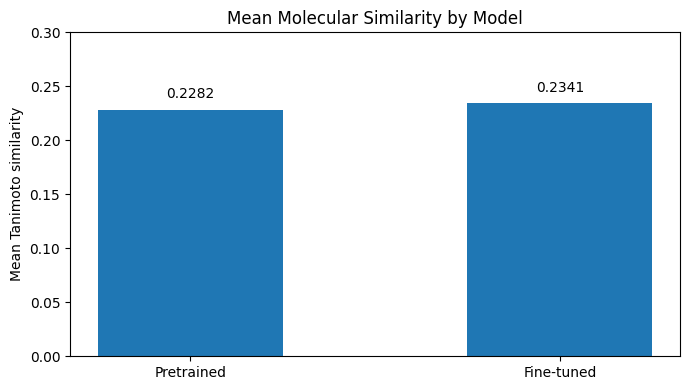

In [18]:
import matplotlib.pyplot as plt

models = ["Pretrained", "Fine-tuned"]
mean_similarity = [
    similarity_comparison["tanimoto_baseline"].mean(),
    similarity_comparison["tanimoto_finetuned"].mean()
]

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(models, mean_similarity, width=0.5)

ax.set_ylabel("Mean Tanimoto similarity")
ax.set_title("Mean Molecular Similarity by Model")
ax.set_ylim(0, 0.30)

for i, value in enumerate(mean_similarity):
    ax.text(i, value + 0.008, f"{value:.4f}",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Figure 1.** Mean Morgan fingerprint Tanimoto similarity for pretrained and fine-tuned MS-BART predictions across 32 validation examples. Molecular fingerprints were generated using a radius of 2 and 2,048 bits. The fine-tuned model showed a small increase in mean similarity from 0.2282 to 0.2341.

The pretrained model achieved a mean Morgan fingerprint Tanimoto similarity of 0.2282, compared with 0.2341 for the fine-tuned model. This represents a small average increase of approximately 0.00594. However, the individual results were mixed, with 12 validation examples improving, 12 worsening, and eight remaining unchanged.

Although fine-tuning changed many of the generated structures, the similarity results do not demonstrate a consistent improvement in their resemblance to the reference molecules. The relatively low mean similarities also indicate that the generated structures generally remained substantially different from their references under this fingerprint representation.

### 6.8 Bootstrap Analysis of Similarity Differences

In [19]:
import numpy as np

differences = similarity_comparison["difference"].dropna().to_numpy()

rng = np.random.default_rng(42)

bootstrap_means = np.array([
    rng.choice(
        differences,
        size=len(differences),
        replace=True
    ).mean()
    for _ in range(5000)
])

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("Mean difference:", round(differences.mean(), 5))
print("Median difference:", round(np.median(differences), 5))
print("Standard deviation:", round(differences.std(ddof=1), 5))
print("95% bootstrap CI:", (round(ci_lower, 5), round(ci_upper, 5)))

Mean difference: 0.00594
Median difference: 0.0
Standard deviation: 0.04962
95% bootstrap CI: (-0.00945, 0.02416)


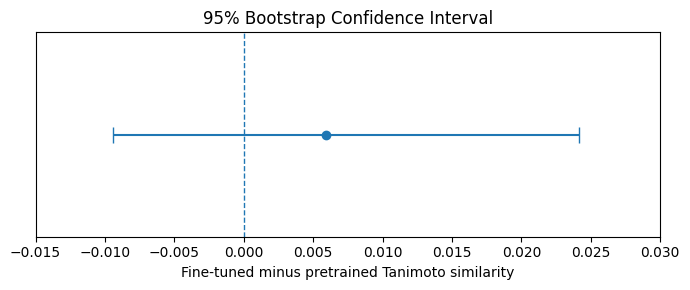

In [20]:
import matplotlib.pyplot as plt

mean_difference = differences.mean()

fig, ax = plt.subplots(figsize=(7, 3))

ax.errorbar(
    mean_difference,
    0,
    xerr=[
        [mean_difference - ci_lower],
        [ci_upper - mean_difference]
    ],
    fmt="o",
    capsize=6
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_xlim(-0.015, 0.030)
ax.set_yticks([])
ax.set_xlabel("Fine-tuned minus pretrained Tanimoto similarity")
ax.set_title("95% Bootstrap Confidence Interval")

plt.tight_layout()
plt.show()

**Figure 2.** Mean paired difference in Morgan fingerprint Tanimoto similarity between fine-tuned and pretrained MS-BART predictions. The point represents the observed mean change (+0.00594), and the horizontal error bar represents the 95% confidence interval estimated from 5,000 bootstrap resamples (−0.00945 to +0.02416). The dashed vertical line indicates zero change.

To further evaluate the similarity differences, I performed 5,000 bootstrap resamples of the paired validation results. The mean difference was approximately 0.00594, with a median of zero and a standard deviation of 0.04962. The resulting 95% bootstrap confidence interval ranged from −0.00945 to 0.02416.

Because this interval includes zero, the observed increase in average similarity does not provide convincing evidence of a reliable improvement from fine-tuning. The limited validation sample also reduces the precision of this estimate. Additionally, the 32 records contain only 29 unique reference structures, so the bootstrap procedure's assumption of independent validation observations may not be fully satisfied.

## 7. Discussion and Limitations

### 7.1 Interpretation of Fine-Tuning Results

The most important finding from this experiment was the difference between successfully fine-tuning a generative model and improving its ability to identify molecular structures. I used full-parameter fine-tuning without LoRA, updating all 104,105,472 model parameters using 128 training examples over one epoch. Both the pretrained and fine-tuned models generated valid molecular structures for all 32 validation examples. However, neither model successfully identified any of the reference molecules, resulting in zero exact matches out of 32 predictions.

After fine-tuning, 24 of the 32 generated SELFIES sequences changed, while eight remained unchanged. This demonstrated that the training process affected the model's output, but those changes did not necessarily represent improved predictions. The Morgan fingerprint similarity analysis showed that 12 predictions became more similar to their references, 12 became less similar, and eight showed no change. Although the mean Tanimoto similarity increased slightly from 0.2282 to 0.2341, the bootstrap confidence interval included zero, so the results did not provide convincing evidence of a consistent improvement.

These findings suggest that the model was able to adapt during training without demonstrating better molecular identification on the validation sample. They also show why evaluating a generative model requires more than monitoring training loss or checking whether its outputs are chemically valid. A model can generate valid structures and respond to parameter updates while still failing to predict the correct molecular identity.

### 7.2 Experimental Limitations and Future Improvements

One of the most significant limitations of this experiment was the small training sample of 128 examples over a single epoch, followed by evaluation on only 32 validation examples. Although this was sufficient to demonstrate that full-parameter fine-tuning could be performed locally, it was not sufficient to establish whether the model could learn a reliable relationship between molecular fingerprint features and complete molecular structures. The inconsistent similarity results also raise questions about whether some types of molecules were better represented in the training sample than others.

Looking back at the experimental design, I would have liked to investigate using fragment-ion information more directly rather than relying exclusively on MIST-derived fingerprints. Molecular fingerprints represent selected structural features, but they do not necessarily preserve how those features are connected within the original molecule. I think of this as having a list of ingredients without knowing the recipe. Several different products could contain the same ingredients, just as multiple molecular structures can share fingerprint features. This becomes even more complicated when the fingerprints are predictions rather than features calculated directly from known structures.

Additional information from the original MS/MS experiment might help distinguish between competing molecular candidates. Precursor mass, adduct identity, fragment-ion formulas, and neutral-loss relationships could provide constraints that are not explicitly available in the fingerprint-token representation. However, fragmentation introduces its own uncertainty. During gas-phase dissociation, ions can undergo rearrangements, proton transfers, and sequential fragmentation, meaning that an observed product ion does not always correspond to a simple bond cleavage in the original molecule (De Vijlder et al., 2018; Ma, 2022).

The difficulty of reconstructing molecular structures from MS/MS data has also been demonstrated in previous research. Stravs et al. (2022) developed MSNovelist, which combines predicted molecular fingerprints with generative molecular structure reconstruction. Although their system generated many valid molecular candidates, it correctly ranked the reference structure first for only 25% of the 3,863 evaluated spectra, while retrieving the correct structure among its generated candidates for 45%. The researchers also acknowledged that certain molecular isomers can exhibit nearly indistinguishable fragmentation behavior. Although their methodology and evaluation differ from my pilot experiment, these findings illustrate the broader challenge that generating chemically plausible molecules does not necessarily lead to accurate molecular identification.

For future research, I would compare fingerprint-only training against a model that incorporates fragmentation evidence, or investigate a combined approach that uses both representations. Generating several molecular candidates and ranking them against experimental evidence may also be more appropriate than requiring a single predicted structure. A larger training dataset, additional epochs, controlled hyperparameter experiments, and evaluation across molecular classes would help determine whether the inconsistent results came from limited training, ambiguity in the input representation, or both.

I am also interested in applying what I learned from this experiment to my current work developing scientific reasoning challenges for advanced AI models. In particular, I would like to explore whether models can distinguish molecular structures with similar fragmentation behavior, recognize when exact identification is unsupported, and correctly interpret structural representations such as SMILES and InChIKeys. This would provide another way to investigate the limitations identified in this project, with an emphasis on evaluating chemical reasoning rather than only generating molecular predictions.

### 7.3 Ethical Considerations and Responsible Model Evaluation

An important ethical consideration in molecular structure generation is the possibility of confusing chemical validity with accurate identification. In this experiment, both models generated valid molecular structures for all 32 validation examples, but neither produced an exact reference match. Reporting only molecular validity could therefore create a misleading impression of model performance. This distinction matters in scientific applications where incorrectly identified molecules could influence subsequent research, chemical characterization, toxicology assessments, or pharmaceutical investigations.

Responsible evaluation requires reporting unsuccessful predictions and uncertainty alongside favorable metrics. Although the fine-tuned model produced a slightly higher mean structural similarity, the bootstrap confidence interval included zero, and individual predictions showed both improvement and deterioration. These results should not be presented as evidence of reliable identification. Predicted structures are better treated as molecular hypotheses requiring independent verification through analytical evidence. For future applications, I would prioritize transparent evaluation, reproducible methods, appropriate confidence reporting, and human review before using model-generated structures to support scientific conclusions.

## 8. Conclusion

This project demonstrated that full-parameter fine-tuning of a pretrained MS-BART model was computationally feasible using my local GPU, without relying on LoRA or external training infrastructure. I successfully trained all 104,105,472 parameters on a 128-example pilot dataset and preserved a checkpoint that could be reloaded for inference. Although the training process changed 24 of the 32 validation predictions, neither the pretrained nor the fine-tuned model correctly identified any reference molecules.

The structural similarity evaluation showed a small increase in mean Tanimoto similarity after fine-tuning, but the results varied across validation examples. The bootstrap confidence interval included zero, providing insufficient evidence that the training produced a reliable improvement. This reinforced one of the central lessons of the experiment: successful model optimization and chemically valid outputs do not necessarily translate into accurate molecular identification.

Looking back, I think the choice of molecular fingerprints as the primary input representation limited the questions I could investigate about the underlying fragmentation chemistry. Future experiments could examine whether incorporating precursor information, fragment ions, neutral-loss relationships, and other chemical constraints would provide the model with a stronger basis for distinguishing molecular structures. These approaches would still need to account for ambiguous fragmentation pathways and gas-phase rearrangements.

Overall, the experiment did not demonstrate improved molecular identification, but it provided a useful assessment of the limitations of this fine-tuning approach. It also changed how I think about evaluating generative models in chemistry. Rather than treating the generation of a valid molecule as the end goal, future work should focus on whether the model can produce chemically supported candidates, distinguish competing structures, and communicate uncertainty in a way that supports reliable scientific interpretation.

## References

Bushuiev, R., Bushuiev, A., de Jonge, N. F., Young, A., Kretschmer, F., Samusevich, R., Heirman, J., Wang, F., Zhang, L., Dührkop, K., Ludwig, M., Haupt, N. A., Kalia, A., Brungs, C., Schmid, R., Greiner, R., Wang, B., Wishart, D. S., Liu, L.-P., . . . Pluskal, T. (2024). MassSpecGym: A benchmark for the discovery and identification of molecules. *Advances in Neural Information Processing Systems, 37*. https://doi.org/10.52202/079017-3491

De Vijlder, T., Valkenborg, D., Lemière, F., Romijn, E. P., Laukens, K., & Cuyckens, F. (2018). A tutorial in small molecule identification via electrospray ionization-mass spectrometry: The practical art of structural elucidation. *Mass Spectrometry Reviews, 37*(5), 607–629. https://doi.org/10.1002/mas.21551

Han, Y., Wang, P., Yu, K., Chen, X., & Chen, L. (2025). MS-BART: Unified modeling of mass spectra and molecules for structure elucidation. *Advances in Neural Information Processing Systems, 38*. https://doi.org/10.52202/085713-3721

Krenn, M., Häse, F., Nigam, A., Friederich, P., & Aspuru-Guzik, A. (2020). Self-referencing embedded strings (SELFIES): A 100% robust molecular string representation. *Machine Learning: Science and Technology, 1*(4), Article 045024. https://doi.org/10.1088/2632-2153/aba947

Ma, X. (2022). Recent advances in mass spectrometry-based structural elucidation techniques. *Molecules, 27*(19), Article 6466. https://doi.org/10.3390/molecules27196466

RDKit. (n.d.). *RDKit: Open-source cheminformatics* [Computer software]. https://www.rdkit.org/

Stravs, M. A., Dührkop, K., Böcker, S., & Zamboni, N. (2022). MSNovelist: De novo structure generation from mass spectra. *Nature Methods, 19*, 865–870. https://doi.org/10.1038/s41592-022-01486-3

Weininger, D. (1988). SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. *Journal of Chemical Information and Computer Sciences, 28*(1), 31–36. https://doi.org/10.1021/ci00057a005